# Customer Churn Prediction Analysis

**Goal:** Predict which e-commerce customers are about to churn (stop buying) so the business can step in *before* they leave.

**Why this matters:** Keeping an existing customer is far cheaper than winning a new one. If we can flag likely churners early, the team can target them with retention offers, check-in emails, or service fixes — and spend that budget only on the customers who actually need it.

**Dataset:** `ecommerce_churn.csv` — 1,896 customers with their tenure, satisfaction, complaint history, ordering behavior, and a `Churn` label (1 = churned, 0 = stayed).

**Workflow:**
0. Imports
1. Exploration — get to know the data
2. Preprocessing — clean missing values, encode categories
3. Train/test split + scaling
4. Train four models (Logistic Regression + Decision Trees at depth 3, 4, 5)
5. Evaluation — Accuracy, Precision, and **Recall (our primary metric)**, plus confusion matrices
6. Conclusion — pick the best model and turn it into business actions

## Step 0 — Imports

We load every tool up front:

- **pandas / numpy** — working with tables and numbers
- **matplotlib / seaborn** — charts
- **train_test_split** — splits the data into a training set (the model learns from it) and a test set (kept hidden, used only to grade the model fairly)
- **StandardScaler** — puts all numeric columns on the same scale so no single column dominates just because its numbers are bigger
- **LogisticRegression / DecisionTreeClassifier** — the two model types we compare
- **accuracy / precision / recall / confusion matrix tools** — the grading metrics

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                           confusion_matrix, ConfusionMatrixDisplay)

# Load the dataset into a DataFrame (a table).
df = pd.read_csv('ecommerce_churn.csv')
print('Dataset loaded:', df.shape[0], 'rows x', df.shape[1], 'columns')

Dataset loaded: 1896 rows x 10 columns


## Task 1 — Exploration

Before building anything, we look at the data: its shape, its types, what's missing, how the target (`Churn`) is distributed, and the basic statistics of every column.

In [2]:
# First 5 rows — a quick visual check that the data loaded correctly.
df.head()

,CustomerID,Churn,Tenure,Gender,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderCount,DaySinceLastOrder
0,54648,0,1.0,Female,4,Single,3,0,2.0,1.0
1,53504,1,3.0,Male,2,Married,9,0,NaN,6.0
2,50722,0,8.0,Male,4,Married,3,0,6.0,4.0
3,50745,0,19.0,Male,4,Divorced,6,0,1.0,3.0
4,53391,1,21.0,Male,3,Single,6,0,2.0,1.0


In [3]:
# Column names, data types, and how many non-missing values each column has.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1896 entries, 0 to 1895
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         1896 non-null   int64  
 1   Churn              1896 non-null   int64  
 2   Tenure             1771 non-null   float64
 3   Gender             1896 non-null   str    
 4   SatisfactionScore  1896 non-null   int64  
 5   MaritalStatus      1896 non-null   str    
 6   NumberOfAddress    1896 non-null   int64  
 7   Complain           1896 non-null   int64  
 8   OrderCount         1833 non-null   float64
 9   DaySinceLastOrder  1797 non-null   float64
dtypes: float64(3), int64(5), str(2)
memory usage: 148.3 KB


In [4]:
# Missing values per column. Missing data must be handled before modeling,
# because scikit-learn models cannot train on blanks.
df.isnull().sum()

CustomerID             0
Churn                  0
Tenure               125
Gender                 0
SatisfactionScore      0
MaritalStatus          0
NumberOfAddress        0
Complain               0
OrderCount            63
DaySinceLastOrder     99
dtype: int64

In [5]:
# How many customers churned vs. stayed?
# 0 = stayed, 1 = churned. A balanced split (close to 50/50) is good news:
# the model can't "cheat" by always predicting the majority class.
print(df['Churn'].value_counts())
print()
print('As percentages:')
print((df['Churn'].value_counts(normalize=True) * 100).round(1))

Churn
0    948
1    948
Name: count, dtype: int64

As percentages:
Churn
0    50.0
1    50.0
Name: proportion, dtype: float64


In [6]:
# Summary statistics for the numeric columns:
# mean, spread (std), min/max, and quartiles.
df.describe()

,CustomerID,Churn,Tenure,SatisfactionScore,NumberOfAddress,Complain,OrderCount,DaySinceLastOrder
count,1896.000000,1896.000000,1771.000000,1896.000000,1896.000000,1896.000000,1833.000000,1797.000000
mean,52758.544304,0.500000,7.629023,3.194093,4.313819,0.380802,2.905074,4.002782
std,1642.162800,0.500132,8.488319,1.366886,2.671286,0.485712,2.863286,3.653947
min,50001.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000
25%,51344.500000,0.000000,1.000000,2.000000,2.000000,0.000000,1.000000,1.000000
50%,52751.500000,0.500000,4.000000,3.000000,3.000000,0.000000,2.000000,3.000000
75%,54173.500000,1.000000,13.000000,4.000000,6.000000,1.000000,3.000000,7.000000
max,55630.000000,1.000000,61.000000,5.000000,22.000000,1.000000,16.000000,46.000000


### What exploration told us

- **1,896 customers, 10 columns.** The target `Churn` is **perfectly balanced**: 948 churned (50%) and 948 stayed (50%).
- **Missing values exist in 3 columns:** `Tenure` (125 missing), `DaySinceLastOrder` (99), and `OrderCount` (63). `Churn` itself has **no** missing values. We fix the gaps in Task 2.
- **Columns live on very different scales** — `Tenure` runs 0–61, `SatisfactionScore` only 1–5. That is exactly why we standardize (scale) the numbers in Task 3.
- Two columns are text categories (`Gender`, `MaritalStatus`) and must be converted to numbers before modeling.

## Task 2 — Preprocessing

Three cleaning steps:

1. **Drop rows with a missing `Churn`.** The target is the answer key — a row without it can't teach the model anything. (In this file there happen to be none, but the step stays in the pipeline so it is safe on any refresh of the data.)
2. **Fill missing numeric values with the median** of each column (`Tenure`, `SatisfactionScore`, `NumberOfAddress`, `OrderCount`, `DaySinceLastOrder`). The median is used instead of the mean because it is not dragged around by extreme outliers (e.g. a `Tenure` of 61 or a `DaySinceLastOrder` of 46).
3. **One-hot encode the text columns** (`Gender`, `MaritalStatus`) with `pd.get_dummies(drop_first=True)`. This turns categories into 0/1 columns a model can read. `drop_first=True` drops one category per column (Female, Divorced) as the reference, avoiding redundant duplicate information.

In [7]:
# Step 1: drop rows where the target itself is missing.
df = df.dropna(subset=['Churn'])
print('Rows after dropping missing Churn:', len(df))

# Step 2: median-impute the numeric columns that can contain gaps.
numeric_cols = ['Tenure', 'SatisfactionScore', 'NumberOfAddress',
                'OrderCount', 'DaySinceLastOrder']
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Confirm: no missing values remain anywhere.
print('Total missing values now:', df.isnull().sum().sum())

Rows after dropping missing Churn: 1896
Total missing values now: 0


In [8]:
# Step 3: one-hot encode the two text columns.
# drop_first=True -> Gender keeps only 'Gender_Male'; MaritalStatus keeps
# 'MaritalStatus_Married' and 'MaritalStatus_Single' (Divorced is the reference).
df = pd.get_dummies(df, columns=['Gender', 'MaritalStatus'],
                    drop_first=True, dtype=int)

# Features (X) = every predictor column. CustomerID is just a row label,
# not customer behavior, so it is excluded. Target (y) = Churn.
X = df.drop(columns=['CustomerID', 'Churn'])
y = df['Churn']

print('Feature columns:', list(X.columns))
print('X shape:', X.shape, '| y shape:', y.shape)
X.head()

Feature columns: ['Tenure', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderCount', 'DaySinceLastOrder', 'Gender_Male', 'MaritalStatus_Married', 'MaritalStatus_Single']
X shape: (1896, 9) | y shape: (1896,)


,Tenure,SatisfactionScore,NumberOfAddress,Complain,OrderCount,DaySinceLastOrder,Gender_Male,MaritalStatus_Married,MaritalStatus_Single
0,1.0,4,3,0,2.0,1.0,0,0,1
1,3.0,2,9,0,2.0,6.0,1,1,0
2,8.0,4,3,0,6.0,4.0,1,1,0
3,19.0,4,6,0,1.0,3.0,1,0,0
4,21.0,3,6,0,2.0,1.0,1,0,1


## Task 3 — Train/Test Split, Then Scaling

We split 80% train / 20% test with `random_state=42` so the split is reproducible (anyone re-running this notebook gets the identical split).

> **A note on when to scale (and why this notebook scales *after* the split):**
> The project template mentions scaling in two places, which is ambiguous. We deliberately fit the scaler **only on the training data** and then apply it to the test data. If we fit it on *all* the data first, information from the test set (its means and spreads) would leak into training — a subtle form of cheating called **data leakage** that makes test scores look better than the model really is. Scaling after the split keeps the test set a fair, honest exam.

In [9]:
# 80% of the data trains the models; 20% is held back to grade them.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)

print('Training set:', X_train.shape[0], 'customers')
print('Test set:    ', X_test.shape[0], 'customers')
print('Churn rate in test set:', round(y_test.mean(), 3))

Training set: 1516 customers
Test set:     380 customers
Churn rate in test set: 0.526


In [10]:
# Fit the scaler on TRAINING data only, then transform both sets.
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train),
                              columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test),
                             columns=X.columns, index=X_test.index)

# After scaling, every training column has mean ~0 and standard deviation ~1.
X_train_scaled.describe().loc[['mean', 'std']].round(2)

,Tenure,SatisfactionScore,NumberOfAddress,Complain,OrderCount,DaySinceLastOrder,Gender_Male,MaritalStatus_Married,MaritalStatus_Single
mean,0.0,-0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Task 4 — Training the Models

Four candidates:

- **Logistic Regression** (`max_iter=1000` so the optimizer has room to converge). A simple, interpretable model — a good baseline, and its coefficients tell us *which* factors push churn up or down.
- **Decision Trees at max_depth 3, 4, and 5.** A tree asks a chain of yes/no questions about a customer. Limiting the depth keeps the tree simple; we test three depths because too shallow underfits (misses real patterns) and too deep overfits (memorizes the training data). `random_state=42` keeps results reproducible.

All four train on the *same* scaled data so the comparison in Task 5 is apples-to-apples. (Trees don't strictly need scaling, but using identical inputs keeps the contest fair.)

In [11]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree (depth=3)': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Decision Tree (depth=4)': DecisionTreeClassifier(max_depth=4, random_state=42),
    'Decision Tree (depth=5)': DecisionTreeClassifier(max_depth=5, random_state=42),
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    print('Trained:', name)

Trained: Logistic Regression
Trained: Decision Tree (depth=3)
Trained: Decision Tree (depth=4)
Trained: Decision Tree (depth=5)


## Task 5 — Evaluation

Three metrics, in plain English:

- **Accuracy** — of all customers, what share did we classify correctly?
- **Precision** — of the customers we *flagged* as churners, how many truly churned? (Low precision = wasted retention offers on happy customers.)
- **Recall** — of the customers who *truly* churned, how many did we catch? (Low recall = churners slipping away unnoticed.)

**Recall is our primary metric.** A missed churner (false negative) is usually far more expensive than a false alarm: the cost of an unnecessary retention offer is small next to losing the customer entirely.

We compute every metric on **both** train and test. The train–test gap is our overfitting check, using this guide:

| Gap (train − test) | Reading |
|---|---|
| < 0.02 | Small — model generalizes well |
| 0.02 – 0.05 | Moderate — watch it |
| > 0.05 | Possible overfitting |

In [12]:
# Score every model on train AND test, and collect the results in one table.
rows = []
for name, model in models.items():
    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)
    rows.append({
        'Model': name,
        'Train Accuracy': accuracy_score(y_train, train_pred),
        'Train Precision': precision_score(y_train, train_pred),
        'Train Recall': recall_score(y_train, train_pred),
        'Test Accuracy': accuracy_score(y_test, test_pred),
        'Test Precision': precision_score(y_test, test_pred),
        'Test Recall': recall_score(y_test, test_pred),
    })

results = pd.DataFrame(rows).set_index('Model')
results.round(4)

,Train Accuracy,Train Precision,Train Recall,Test Accuracy,Test Precision,Test Recall
Model,,,,,,
Logistic Regression,0.8140,0.8018,0.8275,0.8053,0.7944,0.850
Decision Tree (depth=3),0.8015,0.8188,0.7674,0.8132,0.8377,0.800
Decision Tree (depth=4),0.8226,0.8043,0.8463,0.7974,0.7860,0.845
Decision Tree (depth=5),0.8417,0.8649,0.8048,0.8026,0.8453,0.765


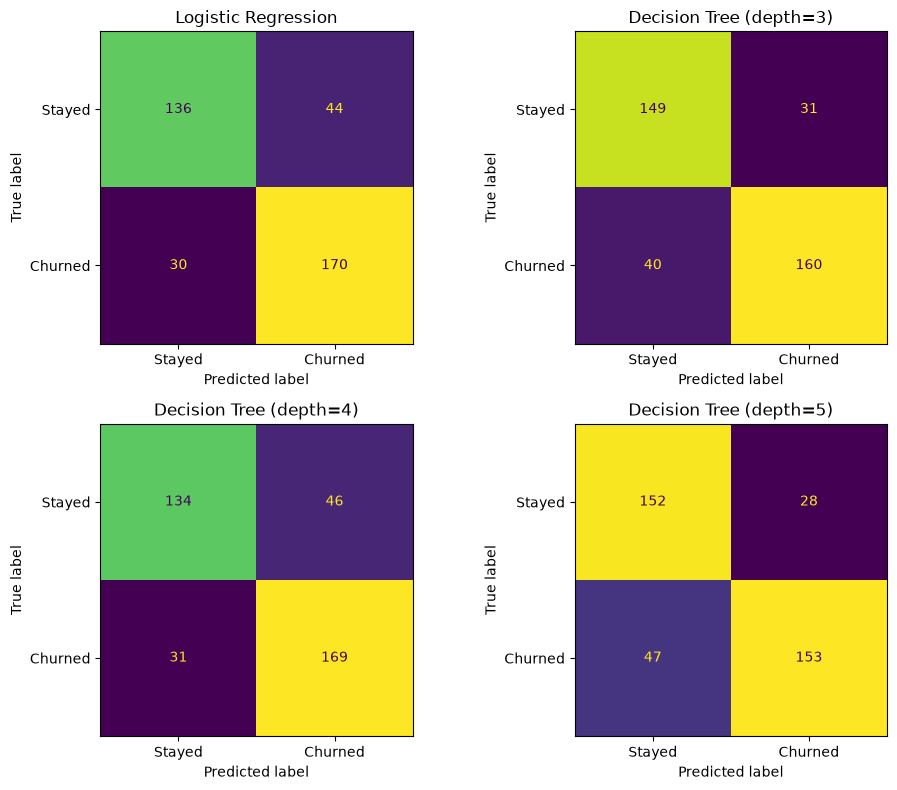

In [13]:
# Confusion matrices on the TEST set.
# Rows = what actually happened, Columns = what the model predicted.
# Top-right (False Positives) = happy customers flagged by mistake.
# Bottom-left (False Negatives) = churners we MISSED — the expensive cell.
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, model) in zip(axes.ravel(), models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, model.predict(X_test_scaled), ax=ax,
        display_labels=['Stayed', 'Churned'], colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Which factors drive churn? (Logistic Regression coefficients)

Because Logistic Regression is interpretable, we can read *why* it flags a customer. On scaled features, a bigger positive coefficient = stronger push toward churn; negative = push toward staying.

In [14]:
# Coefficients of the logistic regression, sorted by strength.
lr = models['Logistic Regression']
coef = pd.Series(lr.coef_[0], index=X.columns).sort_values(key=abs, ascending=False)
coef.round(3)

Tenure                  -1.588
Complain                 0.822
NumberOfAddress          0.499
OrderCount               0.451
DaySinceLastOrder       -0.426
SatisfactionScore        0.350
MaritalStatus_Married   -0.236
MaritalStatus_Single     0.214
Gender_Male              0.148
dtype: float64

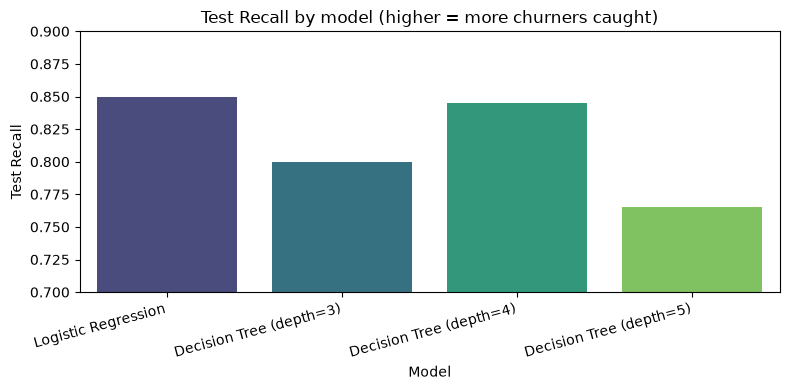

In [15]:
# Test Recall compared visually — higher is better, recall is the metric we select on.
plt.figure(figsize=(8, 4))
sns.barplot(x=results.index, y=results['Test Recall'], hue=results.index,
            legend=False, palette='viridis')
plt.ylim(0.7, 0.9)
plt.ylabel('Test Recall')
plt.title('Test Recall by model (higher = more churners caught)')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

### Reading the results

**Test-set results:**

| Model | Accuracy | Precision | Recall |
|---|---|---|---|
| **Logistic Regression** | 0.805 | 0.794 | **0.850** |
| Decision Tree (depth=3) | 0.813 | 0.838 | 0.800 |
| Decision Tree (depth=4) | 0.797 | 0.786 | 0.845 |
| Decision Tree (depth=5) | 0.803 | 0.845 | 0.765 |

**Overfitting check (train − test gap):**

- **Logistic Regression:** accuracy gap +0.009 (small), recall gap −0.023 — test recall is actually *higher* than train recall. No overfitting at all.
- **Tree depth 3:** small gaps, generalizes fine — but its recall (0.800) leaves 40 of 200 test churners uncaught.
- **Tree depth 4:** accuracy gap +0.025 (moderate), recall gap +0.001. Recall 0.845 — a close second.
- **Tree depth 5:** accuracy and recall gaps ≈ +0.04 (moderate). The deeper tree memorizes training quirks and its test recall *drops* to 0.765 — the classic overfitting pattern.

**Selection:** Recall is the primary metric, and the model must generalize. **Logistic Regression wins on both counts** — highest test recall (0.850) with the smallest train–test gaps.

## Conclusion

### Best model: Logistic Regression

- **Test metrics:** Accuracy **0.805**, Precision **0.794**, Recall **0.850**
- On the 380-customer test set it caught **170 of the 200 customers who actually churned** (only 30 slipped through), at the cost of 44 false alarms — a good trade when a saved customer is worth far more than a retention offer.
- **Why it performed best:** this churn signal is mostly *additive* — each risk factor (a complaint filed, short tenure, many addresses) adds its own push toward churn, which is exactly the shape logistic regression models. The deeper trees chased interactions that turned out to be noise, and paid for it in recall.

### What drives churn (from the coefficients)

1. **Tenure (−1.59)** — by far the strongest factor, and protective: the longer a customer has been with the store, the less likely they are to leave. **New customers are the risk group.**
2. **Complain (+0.82)** — customers who filed a complaint churn much more. A complaint is an early-warning signal, not just a support ticket.
3. **NumberOfAddress (+0.50)** and **OrderCount (+0.45)** also push risk up; **DaySinceLastOrder (−0.43)** — ordering recently is protective.

### Business recommendations

1. **Score every customer monthly with this model** and route the highest-risk segment to the retention team while there is still time to act.
2. **Treat complaints as churn alerts:** anyone who complains gets a follow-up within days, plus a goodwill gesture — that single flag nearly doubles churn risk.
3. **Onboard new customers deliberately** (first-90-days check-ins, a second-order incentive): short tenure is the #1 risk factor.
4. **Accept the false alarms:** with precision at 0.794, roughly 1 in 5 flagged customers would have stayed anyway — cheap insurance compared with the 85% of true churners we now catch in time.